# Predicción de Churn en un Banco


## Contexto
La entidad financiera tuvo una reducción del **15%** de clientes activos en el último trimestre. Para retenerlos diseñó un programa de beneficios (eliminación de cuota de manejo, mejores tasas, retiros ilimitados) y necesita **identificar qué clientes son más propensos a retirarse** para **priorizar** a quién ofrecerlos.

**Objetivo analítico:** Construir un modelo que estime la probabilidad de churn de cada cliente y usarlo para ordenar la campaña de retención.

## Metodología (CRISP-DM)
1. Entendimiento del negocio: problema del banco y objetivo del modelo (ver Contexto)
2. Entendimiento de los datos: calidad, variable objetivo y análisis exploratorio (EDA)
3. Preparación de datos: codificación, escalado, manejo del desbalance y partición train/test
4. Modelado: Optimización (descenso de gradiente), SVM, Redes Neuronales y Ensambles (Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost)
5. Evaluación: comparación y selección del modelo, umbral de decisión e impacto de negocio con Simulación Montecarlo
6. Despliegue: priorización de clientes para la campaña de retención y recomendaciones de monitoreo

## 0. Configuración del notebook

In [1]:
%load_ext autoreload
%autoreload 2

Librerías y configuración de estilo y visualización.

In [2]:
import sys
from pathlib import Path

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [127]:
import pandas as pd
from IPython.display import display

from src import config as cfg
from src import viz
from src.data_understanding import eda, loading, quality
from src.data_preparation import features, imbalance, split
from src.modeling import models, optimization, training
from src.evaluation import metrics, plots

In [5]:
viz.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Entendimiento de los datos
### 2.1 Carga y diccionario de variables

In [6]:
df_raw = loading.load_raw()
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones: 10,127 filas x 21 columnas


,clientnum,attrition_flag,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000


In [7]:
quality.data_dictionary(df_raw)

,descripcion,tipo,nulos,unicos,ejemplo
variable,,,,,
clientnum,Identificador único del cliente,int64,0,10127,768805383
attrition_flag,Variable objetivo: el cliente se fue a otro ba...,str,0,2,Existing Customer
customer_age,Edad del cliente,int64,0,45,45
gender,Sexo del cliente,str,0,2,M
dependent_count,Número de personas económicamente dependientes,int64,0,6,3
education_level,Nivel educativo,str,0,7,High School
marital_status,Estado civil,str,0,4,Married
income_category,Categoría de ingresos,str,0,6,$60K - $80K
card_category,Categoría de tarjeta,str,0,4,Blue


### 2.2 Calidad de los datos

In [8]:
quality.quality_report(df_raw).to_frame()

,valor
filas,10127
columnas,21
celdas nulas,0
filas duplicadas,0
clientnum único,True
celdas 'Unknown',3380
filas con algún 'Unknown',3046
% filas con 'Unknown',30.080


In [9]:
df = loading.load_data()

In [10]:
df.head(5)

,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,churn
clientnum,,,,,,,,,,,,,,,,,,,,
768805383,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061,0
818770008,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105,0
713982108,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000,0
769911858,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760,0
709106358,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000,0


In [11]:
quality.unknown_summary(df)

,n_unknown,% registros,churn % (Unknown),churn % (resto)
variable,,,,
education_level,1519,15.000,16.850,15.930
marital_status,749,7.400,17.220,15.970
income_category,1112,10.980,16.820,15.970


### 2.3 Variable objetivo

,n,%
clase,,
Existing (0),8500,83.930
Attrited (1),1627,16.070


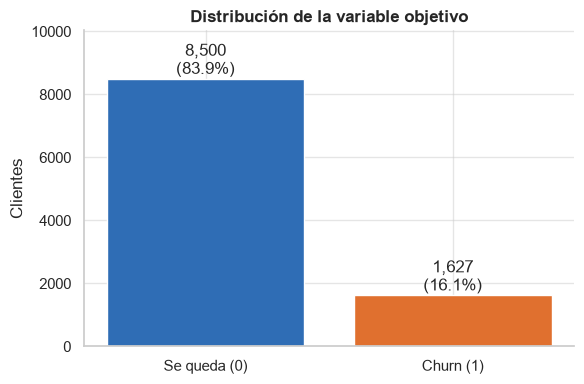

In [12]:
display(quality.target_distribution(df))
fig = eda.plot_target(df)
viz.save_fig(fig, "01_target_distribution")

### 2.4 Estadísticas descriptivas

In [13]:
df[cfg.NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
customer_age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000
dependent_count,"10,127.000",2.346,1.299,0.000,1.000,2.000,3.000,5.000
months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000
total_relationship_count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000
months_inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000
contacts_count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000
credit_limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000"
total_revolving_bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000"
avg_open_to_buy,"10,127.000","7,469.140","9,090.685",3.000,"1,324.500","3,474.000","9,859.000","34,516.000"
total_amt_chng_q4_q1,"10,127.000",0.760,0.219,0.000,0.631,0.736,0.859,3.397


In [14]:
for col in cfg.CATEGORICAL_COLS:
    display(quality.categorical_frequencies(df, col))

,n,%
gender,,
F,5358,52.910
M,4769,47.090


,n,%
education_level,,
Uneducated,1487,14.680
High School,2013,19.880
College,1013,10.000
Graduate,3128,30.890
Post-Graduate,516,5.100
Doctorate,451,4.450
Unknown,1519,15.000


,n,%
marital_status,,
Married,4687,46.280
Single,3943,38.940
Unknown,749,7.400
Divorced,748,7.390


,n,%
income_category,,
Less than $40K,3561,35.160
$40K - $60K,1790,17.680
$60K - $80K,1402,13.840
$80K - $120K,1535,15.160
$120K +,727,7.180
Unknown,1112,10.980


,n,%
card_category,,
Blue,9436,93.180
Silver,555,5.480
Gold,116,1.150
Platinum,20,0.200


### Conclusiones: entendimiento de los datos

- **Base limpia a nivel técnico:** 10.127 clientes, 21 variables, sin valores nulos ni filas duplicadas; `clientnum` es único y se usa solo como índice (no es predictor).
- **Datos faltantes:** `education_level` (15,0%), `income_category` (11,0%) y `marital_status` (7,4%) usan la categoría **"Unknown"**. No son nulos explícitos, pero sí información faltante. La tasa de churn en esos registros es similar a la del resto, por lo que se trabajarán como **categoría propia** en lugar de eliminarlos (se perdería cerca del 30% de la base).
- **Desbalance de clases:** solo el **16,1%** de los clientes hizo churn (1.627 vs 8.500). Un modelo que prediga "nadie se va" tendría 84% de accuracy y sería inútil, así que la **accuracy no sirve como métrica principal**: usaremos Recall, Precision, F1, ROC-AUC y sobre todo PR-AUC de la clase churn, además de técnicas para el desbalance (pesos de clase, SMOTE, ajuste de umbral).
- **`card_category` muy concentrada:** 93% de los clientes tiene tarjeta Blue; Gold y Platinum tienen pocos casos (116 y 20), lo que limita su poder explicativo.
- Las escalas de las variables numéricas son muy distintas (p. ej. `credit_limit` llega a 34.516 y `avg_utilization_ratio` está entre 0 y 1), por lo que **SVM, redes neuronales y la logística por gradiente necesitarán escalado**.

### 2.5 Análisis exploratorio: variables numéricas

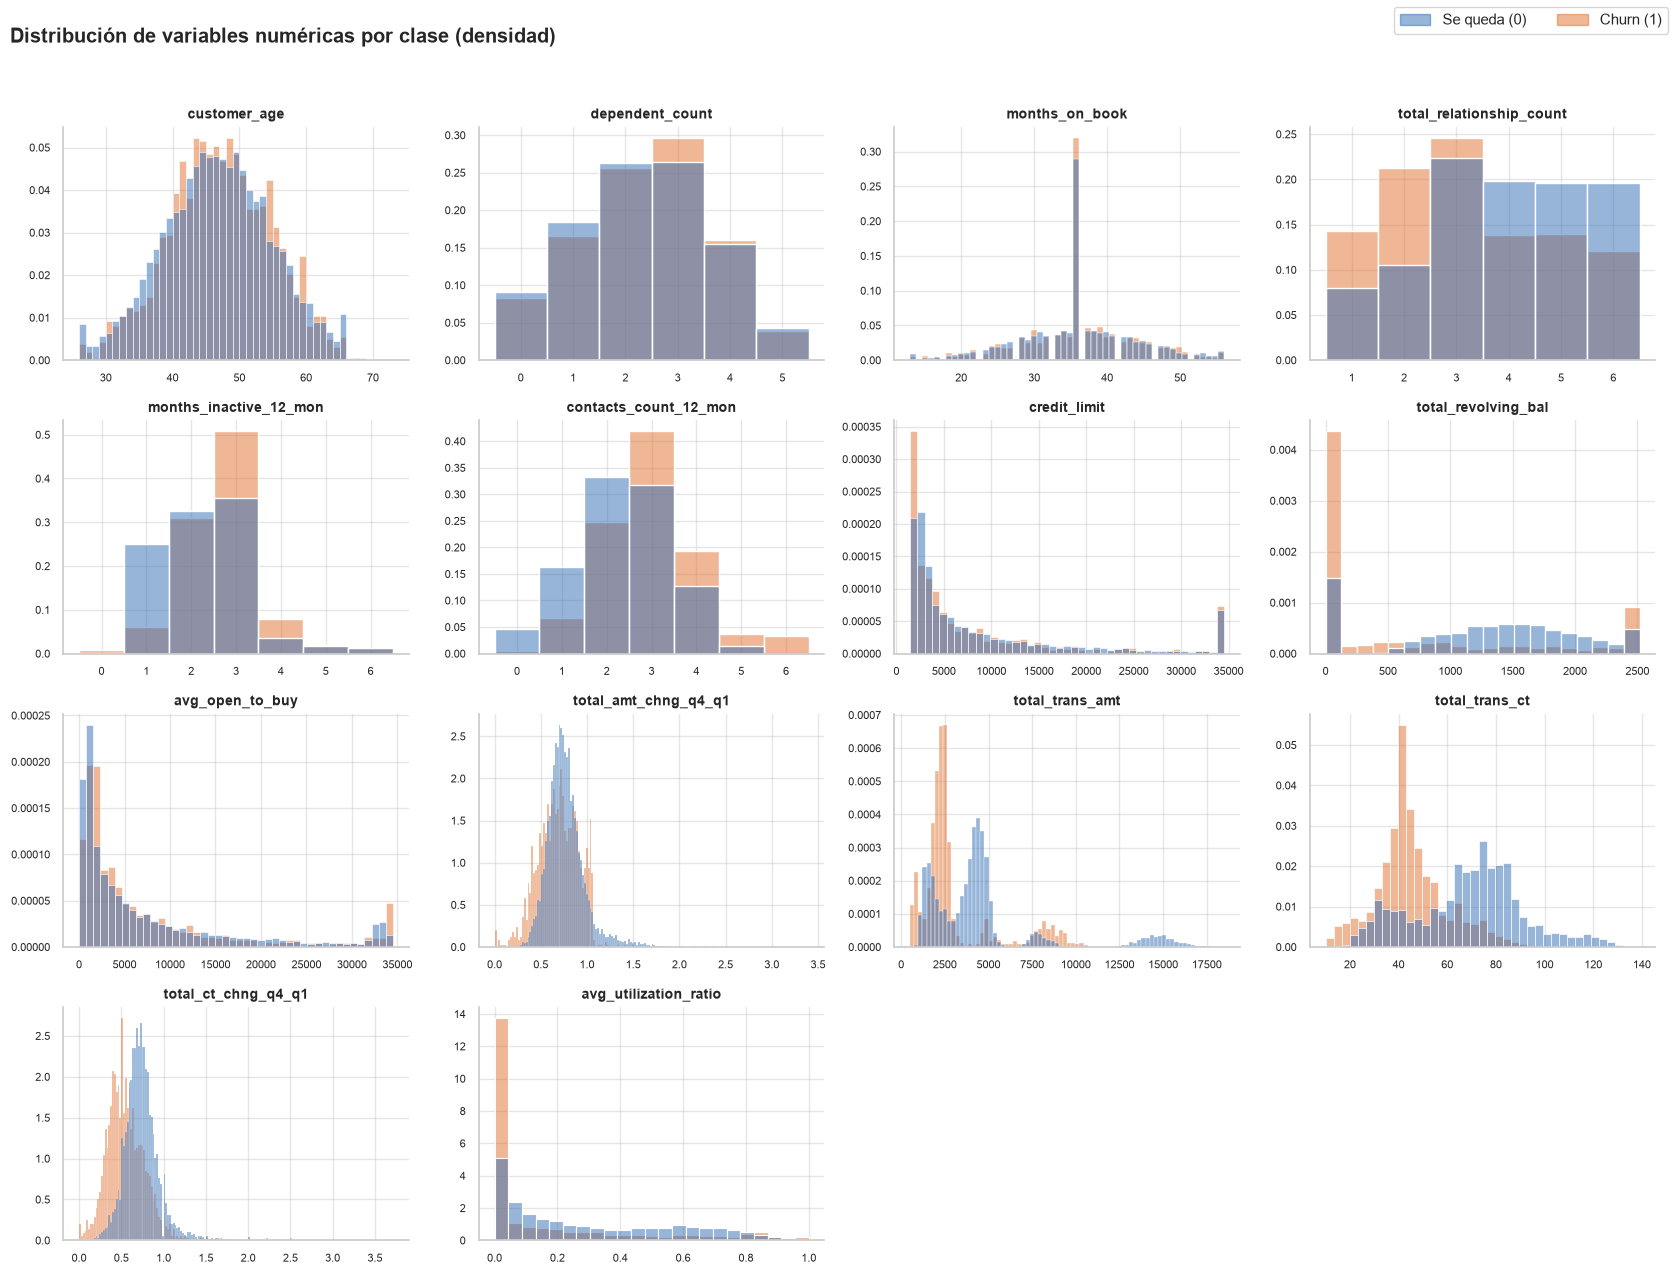

In [15]:
fig = eda.plot_numeric_distributions(df)
viz.save_fig(fig, "02_numeric_distributions")

In [16]:
eda.numeric_medians_by_class(df)

,mediana se queda (0),mediana churn (1),dif %
total_revolving_bal,"1,364.000",0.000,-100.000
avg_utilization_ratio,0.211,0.000,-100.000
months_inactive_12_mon,2.000,3.000,50.000
contacts_count_12_mon,2.000,3.000,50.000
total_trans_amt,"4,100.000","2,329.000",-43.200
total_trans_ct,71.000,43.000,-39.400
total_ct_chng_q4_q1,0.721,0.531,-26.400
total_relationship_count,4.000,3.000,-25.000
credit_limit,"4,643.500","4,178.000",-10.000
total_amt_chng_q4_q1,0.743,0.701,-5.700


In [17]:
for col, table in eda.churn_rate_by_discrete_values(df).items():
    display(table)

,clientes,churn %
dependent_count,,
0,904,14.900
1,1838,14.600
2,2655,15.700
3,2732,17.600
4,1574,16.500
5,424,15.100


,clientes,churn %
total_relationship_count,,
1,910,25.600
2,1243,27.800
3,2305,17.400
4,1912,11.800
5,1891,12.000
6,1866,10.500


,clientes,churn %
months_inactive_12_mon,,
0,29,51.700
1,2233,4.500
2,3282,15.400
3,3846,21.500
4,435,29.900
5,178,18.000
6,124,15.300


,clientes,churn %
contacts_count_12_mon,,
0,399,1.800
1,1499,7.200
2,3227,12.500
3,3380,20.100
4,1392,22.600
5,176,33.500
6,54,100.000


In [18]:
eda.numeric_findings(df).to_frame()

,valor
% churn con balance rotativo = 0,54.900
% no churn con balance rotativo = 0,18.600
clientes con total_trans_amt > 11.000,747
churn % con total_trans_amt > 11.000,0.000
% clientes con months_on_book = 36 (moda),24.300
"% clientes con credit_limit = máximo (34,516)",5.000
correlación credit_limit vs avg_open_to_buy,0.996


**Variables que más diferencian a los clientes que se van (actividad transaccional):**
- `total_trans_ct`: la mediana de transacciones de los clientes con churn es **43**, frente a **71** de los que se quedan.
- `total_trans_amt`: mediana de **2.329** frente a **4.100**. Ninguno de los 747 clientes con monto mayor a 11.000 hizo churn.
- `total_ct_chng_q4_q1`: los que se van tienen una caída más fuerte de transacciones entre Q4 y Q1 (mediana **0,53** frente a **0,72**).
- `total_revolving_bal` y `avg_utilization_ratio`: el **55%** de los clientes con churn tiene balance rotativo en 0, frente al **19%** de los que se quedan. Quien no usa la tarjeta tiene menos vínculo con el banco.

**Variables de relación con el banco:**
- `total_relationship_count`: a menos productos, más churn. Con 1 o 2 productos la tasa de churn es del 26% al 28%; con 4 o más baja a cerca del 11%.
- `months_inactive_12_mon`: la tasa de churn sube de 4,5% (1 mes inactivo) a 30% (4 meses inactivo).
- `contacts_count_12_mon`: la tasa de churn crece con cada contacto, de 1,8% (0 contactos) a 33,5% (5 contactos), y los **54 clientes con 6 contactos se fueron todos**. Los contactos parecen reflejar reclamos o problemas, no gestión comercial.

**Variables que casi no diferencian:** `customer_age`, `dependent_count`, `months_on_book`, `credit_limit` y `avg_open_to_buy` tienen distribuciones muy parecidas en ambas clases.

**Hallazgos de calidad de datos:**
- `months_on_book` tiene un pico anormal en **36 meses (24,3% de los clientes)**. Puede tratarse de un valor por defecto.
- `credit_limit` se acumula en el máximo de **34.516** (5% de los clientes), tal vez un tope del producto.
- `credit_limit` y `avg_open_to_buy` tienen una correlación de **0,996**: son casi la misma información.
- Hay 29 clientes con 0 meses de inactividad y un churn del 52%; es un grupo muy pequeño, así que no se saca conclusión sobre él.

**Lectura de negocio:** el cliente que se va **ya venía desconectándose**: transacciona menos, reduce su actividad entre trimestres, no usa el crédito rotativo, tiene pocos productos y contacta más al banco. Son señales que el banco observa **antes** del retiro, lo que permite anticiparse con la campaña de beneficios.

### 2.6 Análisis exploratorio: variables categóricas
Para cada categoría se calcula la **tasa de churn**. La línea punteada es la tasa general: las barras naranjas están por encima y las azules por debajo. El `n` sobre cada barra indica cuántos clientes hay en la categoría

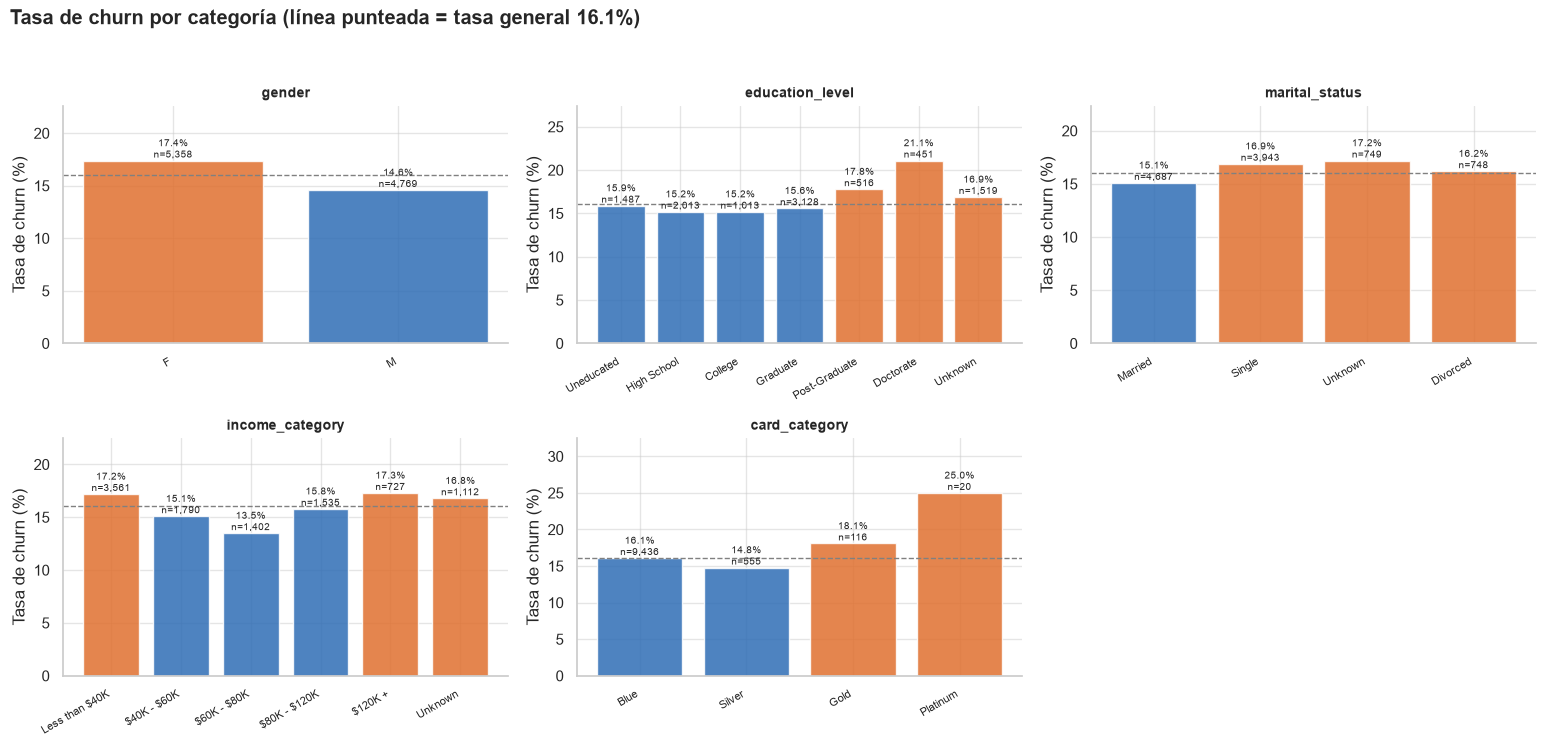

In [19]:
fig = eda.plot_categorical_churn_rate(df)
viz.save_fig(fig, "03_categorical_churn_rate")


In [20]:
for col, table in eda.churn_rate_by_categorical(df).items():
    display(table)

,clientes,churn %
gender,,
F,5358,17.400
M,4769,14.600


,clientes,churn %
education_level,,
Uneducated,1487,15.900
High School,2013,15.200
College,1013,15.200
Graduate,3128,15.600
Post-Graduate,516,17.800
Doctorate,451,21.100
Unknown,1519,16.900


,clientes,churn %
marital_status,,
Married,4687,15.100
Single,3943,16.900
Unknown,749,17.200
Divorced,748,16.200


,clientes,churn %
income_category,,
Less than $40K,3561,17.200
$40K - $60K,1790,15.100
$60K - $80K,1402,13.500
$80K - $120K,1535,15.800
$120K +,727,17.300
Unknown,1112,16.800


,clientes,churn %
card_category,,
Blue,9436,16.100
Silver,555,14.800
Gold,116,18.100
Platinum,20,25.000


#### Prueba chi-cuadrado de independencia
¿Las diferencias en la tasa de churn entre categorías son reales o pueden deberse al azar?

- **H0:** la tasa de churn es la misma en todas las categorías (la variable no está relacionada con el churn).
- **H1:** la tasa de churn depende de la categoría.
- Si el **p-valor < 0,05** se rechaza H0: la variable sí está relacionada con el churn.
- La **V de Cramér** mide la fuerza de la relación (0 = ninguna, 1 = total). Con 10.127 clientes, hasta diferencias pequeñas resultan significativas, así que hay que mirar las dos cosas: si la relación existe (p-valor) y qué tan fuerte es (V de Cramér). Como referencia, V < 0,1 se considera una relación débil.
- **Supuesto:** la prueba es confiable cuando todas las frecuencias esperadas son de al menos 5 (columna `min. esperado`).

In [21]:
eda.chi2_tests(df)

,chi2,gl,p-valor,significativa (p<0.05),V de Cramér,min. esperado
variable,,,,,,
gender,13.870,1,0.000,Sí,0.037,766.200
income_category,12.830,5,0.025,Sí,0.036,116.800
education_level,12.510,6,0.051,No,0.035,72.500
marital_status,6.060,3,0.109,No,0.024,120.200
card_category,2.230,3,0.525,No,0.015,3.200


- `gender`: las mujeres se van más que los hombres (**17,4%** vs **14,6%**). Es la relación más significativa entre las categóricas (p = 0,0002).
- `income_category`: Los extremos están por encima del promedio y el rango $60K - $80K es el más bajo. Es significativa (p = 0,025).
- `education_level`: los niveles más altos se van más (Post-Graduate **17,8%**, Doctorate **21,1%**), pero en conjunto la variable queda en el límite de la significancia (p = 0,051).
- `marital_status`: los casados se van un poco menos (**15,1%**) que los solteros (**16,9%**); la diferencia no es significativa (p = 0,109).
- `card_category`: Platinum muestra **25%** de churn, pero son solo **20 clientes**; la prueba no es significativa (p = 0,525).
- La categoría "Unknown" tiene tasas cercanas al promedio en las tres variables donde aparece, lo que confirma la decisión de mantenerla como una categoría más.

**Fuerza de la relación:** aunque género e ingreso son significativos, **todas las V de Cramér son menores a 0,04**, es decir, relaciones muy débiles. Con más de 10.000 clientes, diferencias de 2 o 3 puntos resultan estadísticamente significativas, pero tienen poco poder para separar a quien se va de quien se queda.

El churn se explica por lo que el cliente hace (transacciones, productos, inactividad, contactos) mucho más que por quién es (género, educación, estado civil, ingresos, tipo de tarjeta). Una campaña segmentada solo por perfil demográfico sería poco efectiva; la priorización debe basarse en variables de comportamiento. Las variables demográficas se mantienen en el modelado porque pueden aportar en combinación con las demás.

### 2.7 Correlación entre variables numéricas
Se usa la correlación de **Spearman** (por rangos) en lugar de Pearson, porque varias variables son asimétricas o tienen muchos ceros. Spearman es robusta a valores extremos y capta relaciones monótonas aunque no sean lineales. Va de -1 a 1: rojo = relación positiva, azul = negativa, blanco = sin relación.

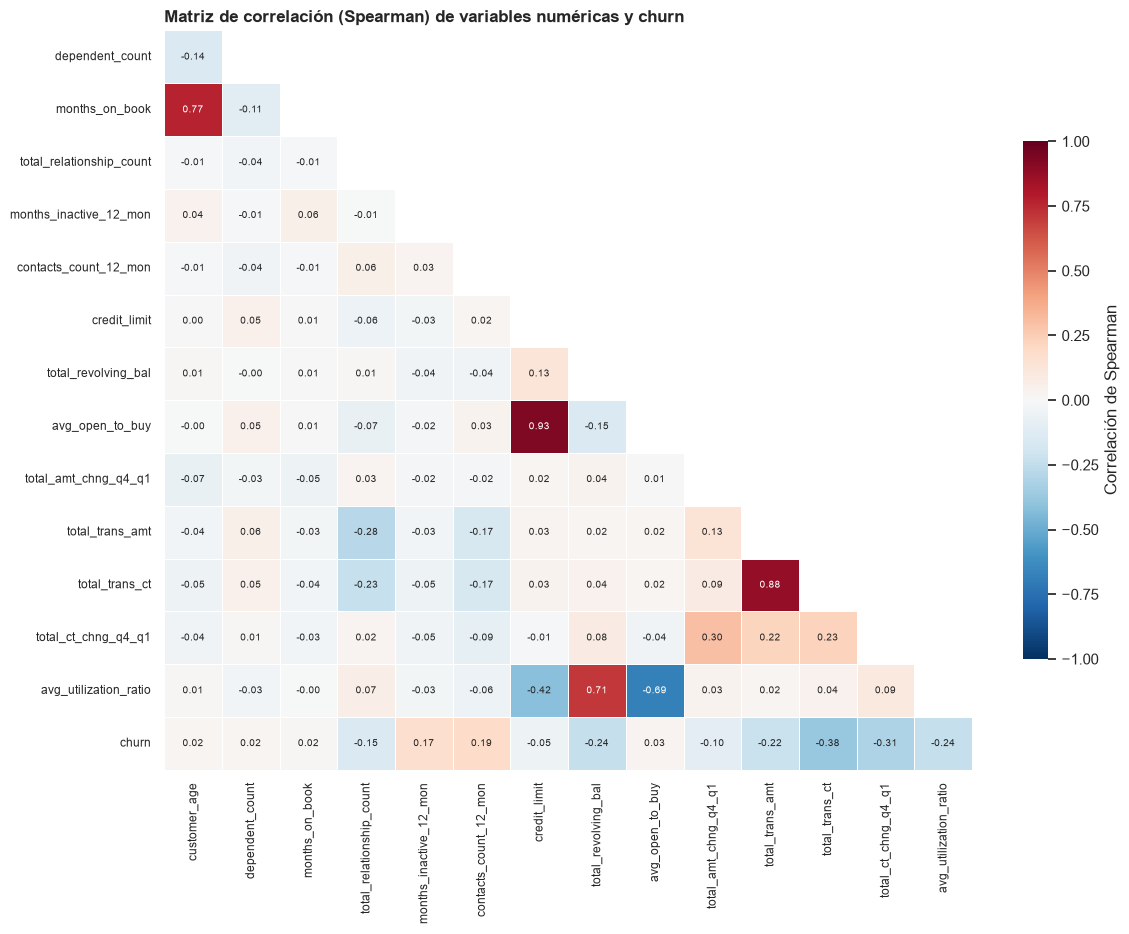

In [22]:
fig = eda.plot_correlation_matrix(df)
viz.save_fig(fig, "04_correlation_matrix")

In [23]:
eda.high_correlation_pairs(df, threshold=0.7)

,variable 1,variable 2,correlación
0,credit_limit,avg_open_to_buy,0.931
1,total_trans_amt,total_trans_ct,0.880
2,customer_age,months_on_book,0.769
3,total_revolving_bal,avg_utilization_ratio,0.709


In [24]:
eda.correlation_with_target(df)

,correlación con churn (spearman)
total_trans_ct,-0.376
total_ct_chng_q4_q1,-0.312
total_revolving_bal,-0.241
avg_utilization_ratio,-0.240
total_trans_amt,-0.224
contacts_count_12_mon,0.189
months_inactive_12_mon,0.172
total_relationship_count,-0.150
total_amt_chng_q4_q1,-0.102
credit_limit,-0.051


In [25]:
eda.derived_variable_checks(df)

,tolerancia,% clientes que la cumplen,máxima diferencia
identidad,,,
avg_open_to_buy = credit_limit - total_revolving_bal,1.000,100.000,0.000
avg_utilization_ratio = total_revolving_bal / credit_limit,0.001,100.000,0.001


**Variables redundantes (|r| ≥ 0,7):**

| Par | Spearman | Explicación | Decisión a evaluar en la Fase 3 |
|---|---|---|---|
| `credit_limit` y `avg_open_to_buy` | 0,93 | `avg_open_to_buy` es **exactamente** `credit_limit - total_revolving_bal` en el 100% de los clientes. No aporta información nueva. | Eliminar `avg_open_to_buy`. |
| `total_trans_amt` y `total_trans_ct` | 0,88 | Quien hace más transacciones mueve más dinero. No son un cálculo una de otra y las dos están entre los mejores predictores. | Mantener ambas y evaluar una variable de **ticket promedio** (`total_trans_amt / total_trans_ct`). |
| `customer_age` y `months_on_book` | 0,77 | Los clientes mayores llevan más tiempo en el banco. Ninguna de las dos se relaciona con el churn (correlación cercana a 0). | Mantener; los modelos con regularización y los ensambles decidirán su peso. |
| `total_revolving_bal` y `avg_utilization_ratio` | 0,71 | `avg_utilization_ratio` es **exactamente** `total_revolving_bal / credit_limit` (redondeada a 3 decimales). Es una relación no lineal, así que la razón sí puede aportar a modelos lineales. | Comparar el desempeño con y sin la razón. |

La redundancia afecta sobre todo a los modelos lineales (regresión logística y SVM lineal): los coeficientes se vuelven inestables y difíciles de interpretar. Los árboles y ensambles se ven poco afectados en desempeño, pero reparten la importancia entre las variables redundantes, lo que confunde la interpretación.

### 2.8 Prueba de Mann-Whitney: ¿las variables numéricas difieren entre clases?
Es el equivalente del chi-cuadrado para las variables numéricas.

- **H0:** la variable tiene la misma distribución en los clientes que se van y en los que se quedan.
- **H1:** las distribuciones son distintas.
- Se usa **Mann-Whitney** y no la prueba t porque varias variables no son normales (asimetrías, muchos ceros). Mann-Whitney no asume normalidad: compara rangos.
- **Tamaño del efecto (r, correlación biserial de rangos):** va de -1 a 1. r < 0 significa que los churners tienen valores **más bajos**; r > 0, **más altos**. Convención: |r| < 0,1 despreciable, < 0,3 pequeño, < 0,5 mediano, ≥ 0,5 grande. Igual que con la V de Cramér, con más de 10.000 clientes casi todo resulta significativo, por eso el tamaño del efecto es lo que indica qué tan útil es la variable.

In [26]:
eda.mann_whitney_tests(df)

,U,p-valor,significativa (p<0.05),efecto r,magnitud
variable,,,,,
total_trans_ct,2826174,<0.0001,Sí,-0.591,grande
total_ct_chng_q4_q1,3522217,<0.0001,Sí,-0.491,mediano
total_revolving_bal,4318784,<0.0001,Sí,-0.375,mediano
avg_utilization_ratio,4320406,<0.0001,Sí,-0.375,mediano
total_trans_amt,4481880,<0.0001,Sí,-0.352,mediano
contacts_count_12_mon,8890849,<0.0001,Sí,0.286,pequeño
months_inactive_12_mon,8687418,<0.0001,Sí,0.256,pequeño
total_relationship_count,5315342,<0.0001,Sí,-0.231,pequeño
total_amt_chng_q4_q1,5806261,<0.0001,Sí,-0.160,pequeño


- **Efecto grande:** `total_trans_ct` (r = **-0,59**) es la variable que más separa a las dos clases: los churners hacen muchas menos transacciones.
- **Efecto mediano:** `total_ct_chng_q4_q1` (**-0,49**), `total_revolving_bal` y `avg_utilization_ratio` (**-0,375** cada una, coinciden porque una es cálculo de la otra) y `total_trans_amt` (**-0,35**).
- **Efecto pequeño:** `contacts_count_12_mon` (**0,29**) y `months_inactive_12_mon` (**0,26**), con signo positivo: los churners tienen más contactos y más inactividad. También `total_relationship_count` (**-0,23**) y `total_amt_chng_q4_q1` (**-0,16**).
- **Efecto despreciable:** `credit_limit`, `avg_open_to_buy` y `dependent_count` son significativas (p < 0,05) pero con |r| < 0,1, es decir, la diferencia existe pero es irrelevante en la práctica. `customer_age` (p = 0,078) y `months_on_book` (p = 0,124) ni siquiera son significativas.

### Conclusiones análisis exploratorio

**1. Perfil del cliente que se va: se desconecta antes de irse.**
Comparado con el que se queda, el cliente que hace churn:
- Hace muchas menos transacciones y mueve menos dinero
- Reduce su actividad entre Q4 y Q1 más que el resto
- No usa el crédito rotativo
- Tiene menos productos con el banco

**2. El comportamiento pesa mucho más que el perfil demográfico.**
- Las variables de actividad tienen efectos grandes o medianos
- Las demográficas tienen relaciones muy débiles

**3. Decisiones**
- **Eliminar `avg_open_to_buy`:** es exactamente `credit_limit - total_revolving_bal`.
- **Evaluar `avg_utilization_ratio`:** es exactamente `total_revolving_bal / credit_limit`; comparar el modelo con y sin ella.
- **Mantener "Unknown" como una categoría más:** su tasa de churn es similar a la del resto y eliminarla haría perder cerca del 30% de la base.
- **Manejar el desbalance** (16,1% de churn): pesos de clase, SMOTE y ajuste del umbral de decisión, evaluando con métricas adecuadas (Recall, PR-AUC) y no con accuracy.

## 3. Preparación de datos

### 3.1 Partición train/test
Antes de cualquier transformación se separa un **20% de los clientes como conjunto de test**. No se usa 70/15/15 para al final hacer una validación con tests independiente en cada modelo creado.

In [27]:
X_train, X_test, y_train, y_test = split.split_data(df)
print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")

X_train: (8101, 19)  |  X_test: (2026, 19)


In [28]:
split.split_summary(y_train, y_test)

,clientes,% del total,churn (1),se queda (0),churn %
conjunto,,,,,
train,8101,80.000,1302,6799,16.070
test,2026,20.000,325,1701,16.040


### 3.2 Ingeniería de variables

1. **Eliminar `avg_open_to_buy`:** es exactamente `credit_limit - total_revolving_bal`.
2. **Crear `avg_ticket` = `total_trans_amt / total_trans_ct`:** monto promedio por transacción. Monto y cantidad están muy correlacionados (0,88); su cociente separa "cuántas veces usa el banco" de "cuánto gasta cada vez".
3. **Mantener `avg_utilization_ratio`** por ahora (es `total_revolving_bal / credit_limit`, una relación no lineal).

Se implementa como un **transformador de sklearn** para que quede dentro del pipeline y se aplique igual al train, al test y a los clientes nuevos cuando el banco use el modelo. No aprende nada de los datos, por lo que no hay riesgo de fuga de información.

In [29]:
fe = features.FeatureEngineer()

In [30]:
X_train_fe = fe.fit_transform(X_train)

In [31]:
features.column_changes(X_train, X_train_fe).to_frame()

,valor
columnas antes,19
columnas después,19
eliminadas,avg_open_to_buy
creadas,avg_ticket


In [32]:
train_fe = X_train_fe.assign(churn=y_train)

In [33]:
train_fe.head(2)

,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,avg_ticket,churn
clientnum,,,,,,,,,,,,,,,,,,,,
787504158,36,F,0,Unknown,Married,Less than $40K,Blue,24,4,3,2,"2,570.000",2230,0.686,1755,42,0.448,0.868,41.786,0
718279008,44,M,3,High School,Single,$60K - $80K,Silver,36,5,2,3,"25,276.000",0,0.849,2282,38,0.583,0.000,60.053,1


In [34]:
display(eda.mann_whitney_tests(train_fe, cols=["total_trans_ct", "total_trans_amt", "avg_ticket"]))

,U,p-valor,significativa (p<0.05),efecto r,magnitud
variable,,,,,
total_trans_ct,1802115,<0.0001,Sí,-0.593,grande
total_trans_amt,2838556,<0.0001,Sí,-0.359,mediano
avg_ticket,4343155,0.2830,No,-0.019,despreciable


In [35]:
display(eda.churn_rate_by_quantile(train_fe, "avg_ticket", q=5))

,clientes,churn %
avg_ticket (cuantiles),,
Q1: 19.1 a 45.1,1621,17.600
Q2: 45.1 a 52.8,1620,17.700
Q3: 52.8 a 58.9,1620,13.500
Q4: 58.9 a 69.6,1620,12.700
Q5: 69.6 a 190.2,1620,19.000


- **`avg_ticket` no separa las clases por sí sola de forma monótona:** en Mann-Whitney su efecto es despreciable
- Sin embargo, la tasa de churn por quintiles tiene **forma de "U"**: los tickets más bajos (**17,6%** y **17,7%**) y los más altos (**19,0%**) se van más que los intermedios (**13,5%** y **12,7%**). Es una relación **no lineal** que Mann-Whitney no detecta, pero que los árboles y ensambles sí pueden aprovechar.
- **Decisión:** `avg_ticket` se mantiene como **variable candidata**. En el modelado se comparará el desempeño con y sin ella (parámetro `add_avg_ticket` del transformador) y se conservará solo si mejora la validación cruzada.

### 3.3 Codificación de variables categóricas y escalado

| Variables | Transformación | Columnas resultantes |
|---|---|---|
| Numéricas (13 originales + `avg_ticket`) | `StandardScaler`: media 0 y desviación 1 | 14 |
| `education_level`, `income_category`, `card_category` (ordinales) | Código según su orden natural (ej. Uneducated = 0 … Doctorate = 5), luego escalado. **"Unknown"** se reemplaza por la **mediana del train** y se agrega un indicador `<variable>_unknown` (1 si el dato era Unknown) | 3 + 2 indicadores (`card_category` no tiene Unknown) |
| `gender` | One-hot eliminando la referencia (M): `gender_F` = 1 si es mujer | 1 |
| `marital_status` | One-hot con "Unknown" como una categoría más, eliminando la referencia (Married, la más frecuente) | 3 |

In [36]:
preprocessor = features.build_preprocessor()

In [38]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print(f"X_train_prep: {X_train_prep.shape}  |  X_test_prep: {X_test_prep.shape}")
preprocessor

X_train_prep: (8101, 23)  |  X_test_prep: (2026, 23)


Pipeline(steps=[('features', FeatureEngineer()),
                ('encode_scale',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['customer_age',
                                                   'dependent_count',
                                                   'months_on_book',
                                                   'total_relationship_count',
                                                   'months_inactive_12_mon',
                                                   'contacts_count_12_mon',
                                                   'credit_limit',
                                                   'total_revolving_bal',
                                                   'total_amt_chng_q4_q1',
                                                   'total_trans_amt',
                                                   'total_trans_ct',
                                                   'total_ct...
                                                                   ColumnTransformer(remainder='passthrough',
                                                                                     transformers=[('scale_codes',
                                                                                                    StandardScaler(),
                                                                                                    ['education_level',
                                                                                                     'income_category',
                                                                                                     'card_category'])],
                                                                                     verbose_feature_names_out=False))]),
                                                  ['education_level',
                                                   'income_category',
                                                   'card_category']),
                                                 ('nom',
                                                  OneHotEncoder(drop=['M',
                                                                      'Married'],
                                                                sparse_output=False),
                                                  ['gender',
                                                   'marital_status'])],
                                   verbose_feature_names_out=False))])

In [39]:
X_test_prep.head()

,customer_age,dependent_count,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,avg_ticket,education_level,income_category,card_category,education_level_unknown,income_category_unknown,gender_F,marital_status_Divorced,marital_status_Single,marital_status_Unknown
clientnum,,,,,,,,,,,,,,,,,,,,,,,
767114958,2.331,-1.810,2.520,0.122,-0.342,-0.411,-0.593,1.111,1.255,-0.335,0.224,-0.504,1.333,-0.611,-1.571,-1.019,-0.248,0,0,0.000,0.000,1.000,0.000
708123033,-0.675,0.502,-0.757,-1.164,-1.331,-1.312,0.319,-1.433,0.676,2.980,1.707,0.031,-1.000,2.873,0.731,-1.019,2.745,0,0,1.000,0.000,1.000,0.000
715424283,-1.927,-1.810,-1.891,0.765,-0.342,-0.411,-0.764,-1.433,2.778,-0.391,-0.623,-0.414,-1.000,-0.051,-0.037,-1.019,-0.248,0,0,1.000,0.000,0.000,0.000
717865008,0.577,-1.039,-0.001,-1.164,-1.331,-1.312,-0.791,-0.859,-0.058,0.011,0.690,1.499,0.179,-0.299,-0.037,-0.239,-0.248,1,0,1.000,0.000,0.000,0.000
710188308,0.577,0.502,0.630,1.409,-0.342,0.490,-0.782,-0.024,0.034,0.159,0.352,0.102,1.743,0.189,0.731,-1.019,-0.248,0,0,1.000,0.000,1.000,0.000


In [40]:
features.preprocessing_summary(X_train_prep)

,media,desv. est.,mín,máx,valores únicos
customer_age,-0.000,1.000,-2.554,3.333,45
dependent_count,0.000,1.000,-1.810,2.042,6
months_on_book,0.000,1.000,-2.900,2.520,44
total_relationship_count,0.000,1.000,-1.807,1.409,6
months_inactive_12_mon,0.000,1.000,-2.320,3.613,7
contacts_count_12_mon,0.000,1.000,-2.213,3.192,7
credit_limit,0.000,1.000,-0.791,2.872,5265
total_revolving_bal,0.000,1.000,-1.433,1.656,1884
total_amt_chng_q4_q1,-0.000,1.000,-3.463,12.023,1092
total_trans_amt,0.000,1.000,-1.136,4.005,4474


In [43]:
X_train_prep["education_level"].unique()

array([-0.0367531 , -0.80411613,  0.73060993, -1.57147916,  2.26533599,
        1.49797296])

- Las 19 variables originales quedan en **23 columnas numéricas**, sin valores faltantes en train ni en test.
- Las variables numéricas y ordinales quedaron con **media 0 y desviación 1** en el train.
- Los indicadores de "Unknown" muestran que el **14,9%** de los clientes del train no tiene nivel educativo y el **10,9%** no tiene ingreso, consistente con lo visto en la sección 2.2.
- **Valores extremos:** `total_amt_chng_q4_q1` y `total_ct_chng_q4_q1` llegan a **12 desviaciones estándar** sobre la media. No se eliminan porque son clientes reales (cambios muy fuertes de actividad entre trimestres). Los árboles y ensambles no se ven afectados.
- `card_category` escalada llega a **8,7** porque casi todos los clientes son Blue (código 0) y muy pocos son Platinum.

### 3.4 Estrategia para el desbalance de clases

Solo el 16% de los clientes hace churn. Un modelo sin ajustes tiende a predecir "se queda" casi siempre, porque así acierta la mayoría de las veces. Se comparan tres estrategias con el **mismo modelo** (regresión logística):

1. **Sin tratamiento** (referencia).
2. **Pesos de clase** (`class_weight="balanced"`): equivocarse con un churner le cuesta al modelo unas 5 veces más que equivocarse con un cliente que se queda. No modifica los datos.
3. **SMOTE:** genera churners **sintéticos** interpolando entre churners reales cercanos, hasta igualar las clases. Se aplica **solo a los datos de entrenamiento de cada fold** (pipeline de `imbalanced-learn`).

**Métricas**:
- **Recall:** de los clientes que se van, ¿qué % detecta el modelo? Es la más importante para el banco: un churner no detectado es un cliente perdido sin intentar retenerlo.
- **Precision:** de los clientes que el modelo marca como churn, ¿qué % se va de verdad? Una precision baja significa gastar beneficios en clientes que no se iban a ir.
- **F1:** equilibrio entre Recall y Precision.
- **ROC-AUC:** probabilidad de que el modelo le dé más riesgo a un churner que a un no churner, elegidos al azar.
- **PR-AUC:** área bajo la curva Precision-Recall. Es más exigente que ROC-AUC cuando la clase positiva es minoritaria.
- **Accuracy balanceada:** promedio del acierto en cada clase (la accuracy normal no sirve con desbalance).


In [45]:
imbalance_models = imbalance.imbalance_experiment_models()

In [46]:
imbalance_summary, imbalance_folds = training.run_experiments(imbalance_models, X_train, y_train)

Sin tratamiento: 2.7 s
Pesos de clase: 1.6 s
SMOTE: 0.1 s


In [47]:
training.format_cv_summary(imbalance_summary)

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
Sin tratamiento,0.62 ± 0.036,0.788 ± 0.02,0.693 ± 0.018,0.934 ± 0.005,0.784 ± 0.018,0.794 ± 0.016,0.06 ± 0.0
Pesos de clase,0.865 ± 0.019,0.547 ± 0.013,0.67 ± 0.01,0.935 ± 0.006,0.772 ± 0.022,0.864 ± 0.008,0.036 ± 0.013
SMOTE,0.843 ± 0.018,0.561 ± 0.014,0.674 ± 0.011,0.932 ± 0.007,0.763 ± 0.021,0.858 ± 0.008,0.051 ± 0.001


- **Sin tratamiento** el modelo detecta solo el **62%** de los churners (Recall 0,620), aunque acierta el **79%** de las veces que marca a alguien (Precision 0,788).
- **Pesos de clase** sube el Recall a **0,865** (detecta 86,5% de los churners) y **SMOTE** a **0,843**, a cambio de bajar la Precision a cerca de **0,55**: de cada 100 clientes marcados, unos 55 se van de verdad.
- **ROC-AUC y PR-AUC prácticamente no cambian** (ROC-AUC entre 0,932 y 0,935). Las estrategias **no hacen al modelo mejor ordenando** a los clientes por riesgo: lo que cambia es **dónde corta** entre "churn" y "no churn". Es equivalente a mover el umbral de decisión, que se optimizará en la fase de evaluación según el costo y beneficio de la campaña.
- Las desviaciones entre folds son pequeñas (0,005 a 0,036), así que las diferencias son estables.

**Decisión:** se usará **pesos de clase** como estrategia principal:
- Logra el mayor Recall con la misma capacidad de ordenamiento.
- Es más simple: no crea datos artificiales. Además, SMOTE interpola también las columnas one-hot y los indicadores, generando valores intermedios (por ejemplo 0,4 en `gender_F`) que no corresponden a clientes reales.
- Los modelos que no aceptan `class_weight` (como la red neuronal `MLPClassifier`) usarán **SMOTE**, y en XGBoost se usará su parámetro equivalente (`scale_pos_weight`).
- El punto de corte final se ajustará con el **umbral de decisión** en la evaluación, usando las métricas de negocio.

### Conclusiones: preparación de datos

**1. Partición.** 80% train (8.101 clientes) y 20% test (2.026), estratificada: las dos partes conservan el 16,1% de churn. El test queda reservado para la evaluación final; la selección de modelos se hace con validación cruzada estratificada de 5 folds sobre el train.

**2. Variables.** De las 19 variables originales se pasa a **23 columnas numéricas**

**3. Sin fuga de información.** Todo el preprocesamiento está dentro de un **pipeline**: se ajusta solo con los datos de entrenamiento.

**4. Desbalance.** Se usará **pesos de clase** (`class_weight="balanced"`) como estrategia principal: subió el Recall de 0,62 a 0,865 sin cambiar la capacidad de ordenamiento (ROC-AUC 0,935) y sin crear datos artificiales. SMOTE se usará en los modelos que no aceptan pesos, y el punto de corte final se ajustará con el umbral de decisión en la evaluación.

## 4. Modelado

Se aplican diferentes modelos, todos con el mismo preprocesamiento y evaluados con validación cruzada estratificada de 5 folds sobre el train.

1. **Optimización:** regresión logística entrenada con descenso de gradiente.
2. **Support Vector Machines:** lineal y con kernels.
3. **Redes neuronales:** perceptrón multicapa y regularización.
4. **Ensambles:** Bagging, Random Forest, AdaBoost, Gradient Boosting y XGBoost.

La **Simulación Montecarlo** se usa en la evaluación para estimar el impacto de negocio del modelo elegido.

### 4.1 Optimización: regresión logística con descenso de gradiente

Entrenar un modelo es un **problema de optimización**: encontrar los coeficientes que minimizan una función de pérdida. Para la regresión logística la pérdida es la **log-loss** (entropía cruzada), que castiga dar probabilidad baja a un cliente que sí se fue y viceversa.

In [61]:
sgd_curve = optimization.sgd_loss_curve(X_train_prep, y_train, eta0=0.001, epochs=50)

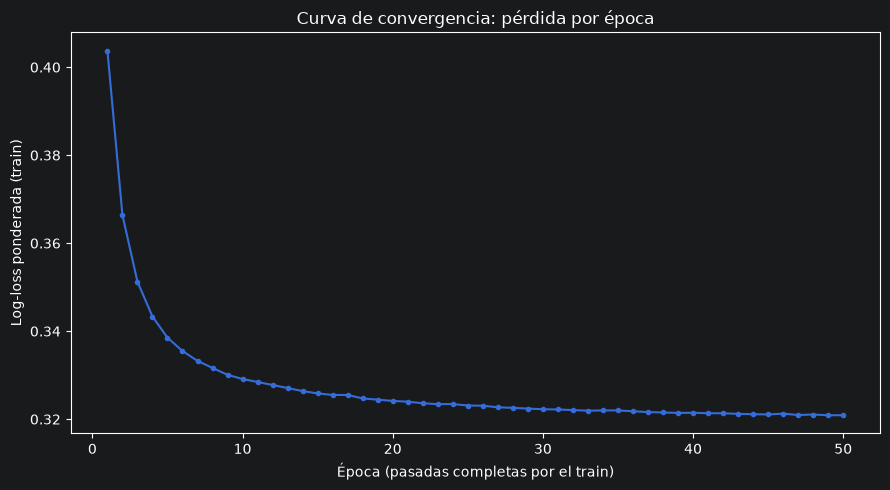

In [62]:
fig = optimization.plot_loss_curves(sgd_curve)
viz.save_fig(fig, "05_sgd_convergence")

In [74]:
optimization.loss_curve_summary(sgd_curve).T

,eta0=0.001
pérdida época 1,0.404
pérdida final,0.321
pérdida mínima,0.321
época del mínimo,49.000
variación últimas 10 épocas,0.001


- La pérdida baja rápido en las primeras épocas (parte de **0,404** en la época 1) y luego se aplana: el algoritmo se está acercando al mínimo.
- Al final llega a **0,321**, y en las últimas 10 épocas varía apenas **0,001**

In [75]:
lr_curves = optimization.loss_curves_by_learning_rate(
    X_train_prep, y_train, eta0_values=[0.0001, 0.001, 0.01, 0.1, 1.0], epochs=50
)

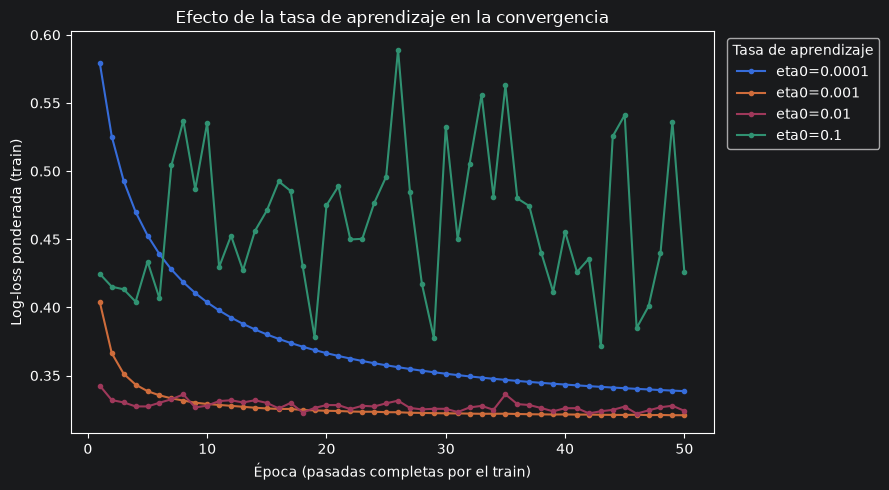

In [76]:
fig = optimization.plot_loss_curves(
    lr_curves.drop(columns="eta0=1.0"),
    title="Efecto de la tasa de aprendizaje en la convergencia",
)
viz.save_fig(fig, "06_sgd_learning_rate")

In [77]:
optimization.loss_curve_summary(lr_curves)

,pérdida época 1,pérdida final,pérdida mínima,época del mínimo,variación últimas 10 épocas
eta0=0.0001,0.579,0.339,0.339,50,0.004
eta0=0.001,0.404,0.321,0.321,49,0.001
eta0=0.01,0.343,0.324,0.322,46,0.006
eta0=0.1,0.425,0.426,0.371,43,0.170
eta0=1.0,2.288,3.227,2.115,4,2.398


La tasa de aprendizaje es un parámetro importante del descenso de gradiente, con una tasa de aprendizaje adecuada (0,001) la pérdida baja rápido y se estabiliza en la pérdida más baja.

#### Desempeño en validación cruzada
Se evalúa el modelo con la tasa de aprendizaje elegida y pesos de clase, con la misma validación cruzada de 5 folds.

In [78]:
cv_folds = {"Regresión logística (sklearn)": imbalance_folds["Pesos de clase"]}

In [79]:
sgd_pipeline = imbalance.make_pipeline(optimization.make_sgd(eta0=0.001), "class_weight")

In [80]:
_, sgd_folds = training.run_experiments({"Regresión logística SGD": sgd_pipeline}, X_train, y_train)

Regresión logística SGD: 2.5 s


In [81]:
cv_folds.update(sgd_folds)

In [82]:
training.format_cv_summary(training.summarize_cv(cv_folds))

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
Regresión logística (sklearn),0.865 ± 0.019,0.547 ± 0.013,0.670 ± 0.010,0.935 ± 0.006,0.772 ± 0.022,0.864 ± 0.008,0.036 ± 0.013
Regresión logística SGD,0.869 ± 0.020,0.538 ± 0.017,0.664 ± 0.012,0.934 ± 0.006,0.767 ± 0.019,0.863 ± 0.009,0.071 ± 0.003


#### Conclusiones: optimización

- El descenso de gradiente **convergió** con una tasa de aprendizaje adecuada (0,001); tasas muy pequeñas no alcanzan a converger y tasas grandes oscilan o divergen.
- En validación cruzada, la regresión logística con SGD logra prácticamente el **mismo desempeño** que la de sklearn.
- La regresión logística con SGD detecta el **86,9%** de los churners (Recall 0,869). Es la **línea base** contra la que se compararán SVM, redes neuronales y ensambles: un modelo más complejo debe superarla para justificar su uso.

### 4.2 Support Vector Machines (SVM)
Una SVM busca la **frontera que separa a las dos clases con el mayor margen posible**. Se probaraán 3 kerns.

- Kernel lineal
- Kernels no lineales
  - RBF (gaussiano)
  - Polinomial

In [84]:
svm_summary, svm_folds = training.run_experiments(models.svm_kernel_models(), X_train, y_train)

SVM lineal: 2.9 s
SVM RBF: 2.0 s
SVM polinomial (grado 3): 2.0 s


In [85]:
cv_folds.update(svm_folds)

In [86]:
training.format_cv_summary(svm_summary)

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
SVM lineal,0.869 ± 0.018,0.544 ± 0.017,0.669 ± 0.014,0.935 ± 0.005,0.768 ± 0.021,0.865 ± 0.009,0.496 ± 0.009
SVM RBF,0.896 ± 0.025,0.693 ± 0.024,0.781 ± 0.021,0.970 ± 0.004,0.860 ± 0.012,0.910 ± 0.014,0.192 ± 0.013
SVM polinomial (grado 3),0.843 ± 0.040,0.708 ± 0.021,0.769 ± 0.018,0.958 ± 0.009,0.841 ± 0.017,0.888 ± 0.018,0.209 ± 0.011


#### Observaciones: kernels de SVM
- **SVM lineal** rinde igual que la regresión logística: ambos modelos tienen una frontera lineal, así que llegan al mismo límite.
- **SVM RBF** es claramente mejor: PR-AUC sube a **0,860** y ROC-AUC a **0,970**. Más precisión (**0,693** frente a **0,544** del lineal).
- **SVM polinomial** también mejora sobre el lineal (PR-AUC **0,841**), pero queda por debajo de RBF y es la más inestable entre folds (desviación del Recall **0,040**).
- Se continúa con **RBF** para ajustar sus hiperparámetros (C y gamma).

#### Ajuste de hiperparámetros de SVM RBF
- **C** (penalización de errores): 0,1 · 1 · 10 · 100 · 1.000.
- **gamma** (qué tan local es la influencia de cada cliente): 0,001 · 0,003 · 0,01 · 0,03 · 0,1 · 1. Con gamma pequeño cada cliente influye en una zona amplia (frontera suave); con gamma grande solo influye en su vecindad inmediata (frontera muy irregular, riesgo de sobreajuste).

In [88]:
svm_search = training.tune_model(models.svm_pipeline(kernel="rbf"), models.SVM_RBF_GRID, X_train, y_train)

30 combinaciones x 5 folds en 15.4 s


In [92]:
svm_search.best_params_

{'model__C': 10, 'model__gamma': 0.03}

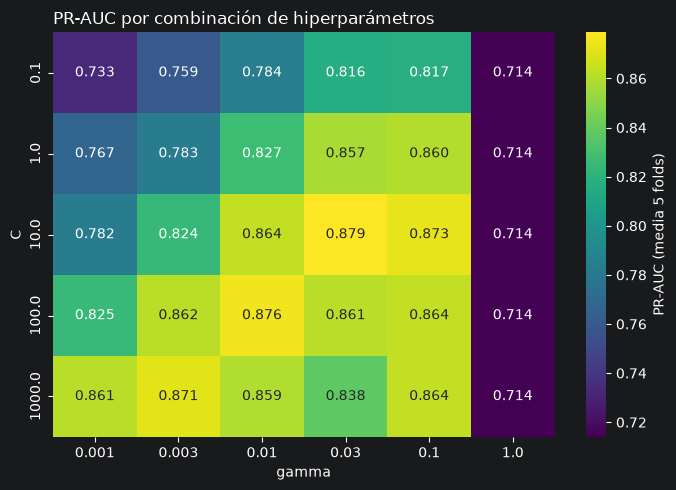

In [89]:
fig = plots.plot_grid_heatmap(svm_search, param_x="model__gamma", param_y="model__C", metric="pr_auc")
viz.save_fig(fig, "07_svm_rbf_grid")

In [100]:
display(training.tuning_results(svm_search, top=5))

,C,gamma,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,desv PR-AUC
ranking,,,,,,,,,
1,10.000,0.030,0.876,0.715,0.787,0.971,0.879,0.904,0.007
2,100.000,0.010,0.881,0.692,0.775,0.969,0.876,0.903,0.008
3,10.000,0.100,0.783,0.815,0.798,0.966,0.873,0.874,0.008
4,"1,000.000",0.003,0.892,0.677,0.770,0.967,0.871,0.905,0.008
5,10.000,0.010,0.908,0.651,0.758,0.968,0.864,0.907,0.011


In [101]:
_, svm_best_folds = training.run_experiments({"SVM RBF ajustado": svm_search.best_estimator_}, X_train, y_train)
cv_folds.update(svm_best_folds)
training.format_cv_summary(training.summarize_cv(cv_folds))

SVM RBF ajustado: 2.6 s


,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
Regresión logística (sklearn),0.865 ± 0.019,0.547 ± 0.013,0.670 ± 0.010,0.935 ± 0.006,0.772 ± 0.022,0.864 ± 0.008,0.036 ± 0.013
Regresión logística SGD,0.869 ± 0.020,0.538 ± 0.017,0.664 ± 0.012,0.934 ± 0.006,0.767 ± 0.019,0.863 ± 0.009,0.071 ± 0.003
SVM lineal,0.869 ± 0.018,0.544 ± 0.017,0.669 ± 0.014,0.935 ± 0.005,0.768 ± 0.021,0.865 ± 0.009,0.496 ± 0.009
SVM RBF,0.896 ± 0.025,0.693 ± 0.024,0.781 ± 0.021,0.970 ± 0.004,0.860 ± 0.012,0.910 ± 0.014,0.192 ± 0.013
SVM polinomial (grado 3),0.843 ± 0.040,0.708 ± 0.021,0.769 ± 0.018,0.958 ± 0.009,0.841 ± 0.017,0.888 ± 0.018,0.209 ± 0.011
SVM RBF ajustado,0.876 ± 0.025,0.715 ± 0.031,0.787 ± 0.020,0.971 ± 0.004,0.879 ± 0.008,0.904 ± 0.012,0.219 ± 0.002


- La mejor combinación es **C = 10 y gamma = 0,03**
- **No hay un único punto óptimo sino una "diagonal" de buenas combinaciones:** C = 100 con gamma = 0,01 (**0,876**) y C = 1.000 con gamma = 0,003 (**0,871**) rinden casi igual. Al subir C (menos tolerancia a errores) conviene bajar gamma (frontera más suave): los dos parámetros se compensan para controlar la complejidad del modelo.
- El modelo ajustado tiene Recall **0,876**, Precision **0,715** y ROC-AUC **0,971**. Frente a la línea base lineal, detecta una proporción similar de churners pero con **mucha más precisión**: hay menos clientes marcados por error, lo que significa beneficios mejor dirigidos.

### 4.3 Redes neuronales
Se usa un **perceptrón multicapa** (`MLPClassifier` de sklearn): una red **feed-forward** donde la información va de la capa de entrada (las 23 variables) a una o más **capas ocultas** y luego a la neurona de salida, que da la probabilidad de churn.

Primero se comparan **arquitecturas** (número de capas ocultas y neuronas) con los demás parámetros por defecto (regularización L2 alpha = 0,0001, sin early stopping):
- Una capa oculta de 16, 32 o 64 neuronas.
- Dos capas ocultas: (32, 16) y (64, 32).

In [102]:
mlp_summary, mlp_folds = training.run_experiments(models.mlp_architecture_models(), X_train, y_train)

MLP (16,): 5.7 s
MLP (32,): 7.4 s
MLP (64,): 7.5 s
MLP (32, 16): 4.5 s
MLP (64, 32): 2.7 s


In [103]:
training.format_cv_summary(mlp_summary)

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
"MLP (16,)",0.869 ± 0.016,0.737 ± 0.026,0.797 ± 0.012,0.970 ± 0.003,0.886 ± 0.009,0.905 ± 0.006,3.094 ± 0.299
"MLP (32,)",0.818 ± 0.034,0.776 ± 0.010,0.796 ± 0.015,0.969 ± 0.003,0.886 ± 0.012,0.886 ± 0.016,5.645 ± 0.297
"MLP (64,)",0.819 ± 0.024,0.793 ± 0.015,0.806 ± 0.014,0.971 ± 0.005,0.890 ± 0.010,0.889 ± 0.012,5.744 ± 0.286
"MLP (32, 16)",0.814 ± 0.028,0.791 ± 0.009,0.802 ± 0.012,0.970 ± 0.003,0.885 ± 0.005,0.886 ± 0.013,4.128 ± 0.228
"MLP (64, 32)",0.811 ± 0.044,0.800 ± 0.019,0.805 ± 0.020,0.972 ± 0.003,0.885 ± 0.012,0.886 ± 0.020,2.495 ± 0.189


#### Observaciones: arquitecturas
- **Todas las arquitecturas rinden prácticamente igual:** PR-AUC entre **0,885** y **0,890**, y ROC-AUC entre **0,969** y **0,972**. Las diferencias son menores que la desviación entre folds (**0,005** a **0,012** en PR-AUC), así que **agregar neuronas o capas no mejora** el modelo.
- Todas superan a la SVM RBF ajustada (PR-AUC **0,879**) y a la línea base lineal (**0,768**).
- Lo que sí cambia es el **balance entre Recall y Precision**: la red más pequeña, (16), detecta más churners (Recall **0,869**, Precision **0,737**), mientras que las más grandes marcan menos clientes pero con más acierto (por ejemplo (64, 32): Recall **0,811**, Precision **0,800**). Las redes grandes son más inestables en Recall (desviación **0,044** en (64, 32)).
- Se continúa con **una capa de 64 neuronas**, la de mayor PR-AUC (**0,890**), para estudiar la **regularización**: es en las redes con más parámetros donde la regularización tiene más efecto. Si la regularización no mejora el resultado, por **parsimonia** se preferiría la red más simple (16), que rinde igual.

#### Regularización L2

Se busca el mejor alpha para la red de una capa de 64 neuronas con `GridSearchCV` (mismos 5 folds, optimizando PR-AUC), en escala logarítmica: 0,0001 · 0,001 · 0,01 · 0,1 · 1 · 10.

In [104]:
mlp_search = training.tune_model(
    models.mlp_pipeline(hidden_layer_sizes=(64,)), models.MLP_ALPHA_GRID, X_train, y_train
)

6 combinaciones x 5 folds en 20.8 s


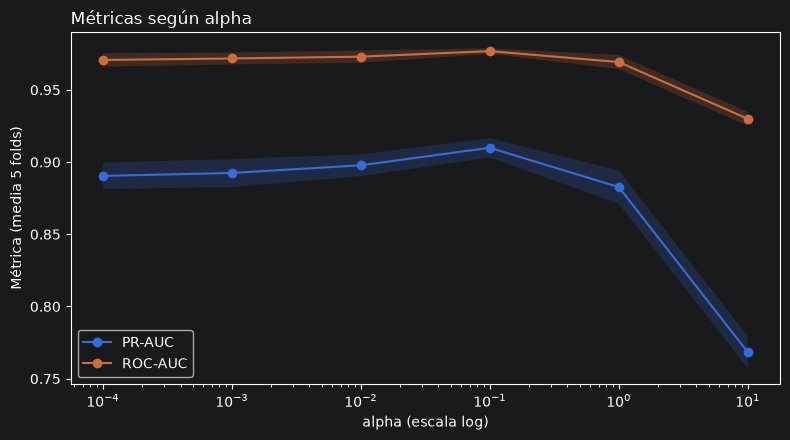

In [105]:
fig = plots.plot_param_curve(mlp_search, param="model__alpha", metrics=("pr_auc", "roc_auc"))
viz.save_fig(fig, "08_mlp_alpha")

In [106]:
training.tuning_results(mlp_search)

,alpha,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,desv PR-AUC
ranking,,,,,,,,
1,0.1,0.866,0.787,0.825,0.977,0.910,0.911,0.007
2,0.01,0.823,0.810,0.816,0.973,0.898,0.893,0.008
3,0.001,0.805,0.812,0.808,0.972,0.892,0.885,0.010
4,0.0001,0.819,0.793,0.806,0.971,0.890,0.889,0.009
5,1.0,0.882,0.701,0.781,0.969,0.883,0.905,0.012
6,10.0,0.846,0.552,0.668,0.930,0.768,0.857,0.011


- La regularización **sí mejora** la red: con **alpha = 0,1** la PR-AUC sube a **0,910** (desde **0,890** con el valor por defecto 0,0001) y la ROC-AUC a **0,977**.
- Además de mejorar el ordenamiento, sube el **Recall a 0,866** manteniendo una Precision de **0,787**: detecta más churners sin marcar más clientes por error.

#### Early stopping

Se compara la red elegida (64 neuronas, alpha = 0,1) **con y sin early stopping**, con la misma validación cruzada de 5 folds.

In [107]:
mlp_candidates = {
    "MLP (64) alpha=0.1": models.mlp_pipeline(hidden_layer_sizes=(64,), alpha=0.1),
    "MLP (64) alpha=0.1 + early stopping": models.mlp_pipeline(hidden_layer_sizes=(64,), alpha=0.1, early_stopping=True),
}

In [108]:
mlp_es_summary, mlp_es_folds = training.run_experiments(mlp_candidates, X_train, y_train)
training.format_cv_summary(mlp_es_summary)

MLP (64) alpha=0.1: 5.5 s
MLP (64) alpha=0.1 + early stopping: 2.2 s


,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
MLP (64) alpha=0.1,0.866 ± 0.035,0.787 ± 0.020,0.825 ± 0.022,0.977 ± 0.002,0.910 ± 0.008,0.911 ± 0.018,2.745 ± 0.410
MLP (64) alpha=0.1 + early stopping,0.874 ± 0.031,0.723 ± 0.028,0.791 ± 0.021,0.970 ± 0.005,0.888 ± 0.015,0.905 ± 0.015,0.698 ± 0.236


In [109]:
mlp_curves = training.mlp_training_curves(
    {
        "MLP (64) alpha=0.1": models.mlp_pipeline(hidden_layer_sizes=(64,), alpha=0.1),
        "MLP (64) alpha=0.1 + early stopping": models.mlp_pipeline(hidden_layer_sizes=(64,), alpha=0.1, early_stopping=True),
    },
    X_train, y_train,
)

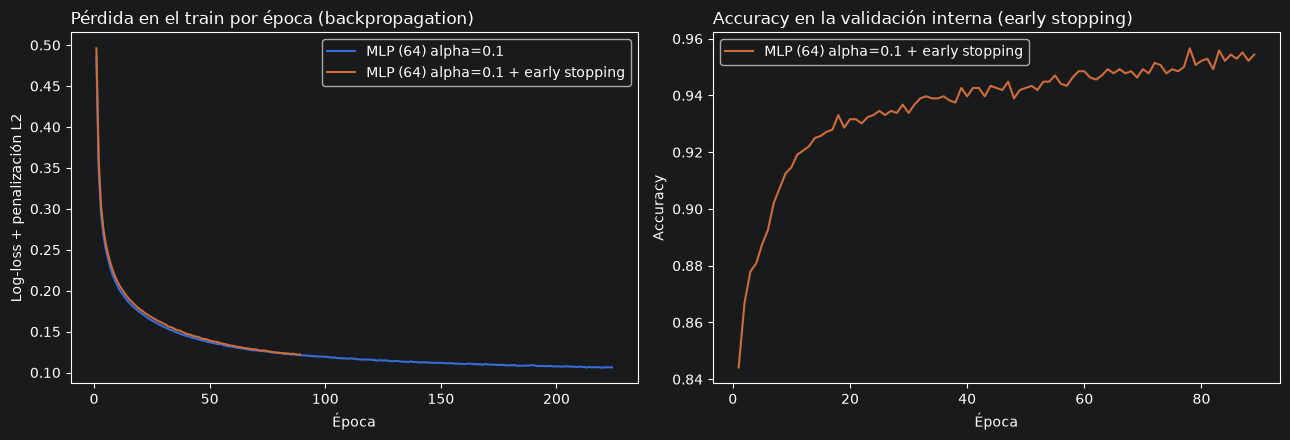

In [110]:
fig = plots.plot_mlp_curves(mlp_curves)
viz.save_fig(fig, "09_mlp_training_curves")

In [111]:
training.curves_summary(mlp_curves)

,épocas entrenadas,pérdida época 1,pérdida final,mejor accuracy validación interna
modelo,,,,
MLP (64) alpha=0.1,224,0.486,0.106,-
MLP (64) alpha=0.1 + early stopping,89,0.496,0.122,0.957


In [113]:
cv_folds["Red neuronal MLP (64) alpha=0.1"] = mlp_es_folds["MLP (64) alpha=0.1"]
training.format_cv_summary(training.summarize_cv(cv_folds))

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
Regresión logística (sklearn),0.865 ± 0.019,0.547 ± 0.013,0.670 ± 0.010,0.935 ± 0.006,0.772 ± 0.022,0.864 ± 0.008,0.036 ± 0.013
Regresión logística SGD,0.869 ± 0.020,0.538 ± 0.017,0.664 ± 0.012,0.934 ± 0.006,0.767 ± 0.019,0.863 ± 0.009,0.071 ± 0.003
SVM lineal,0.869 ± 0.018,0.544 ± 0.017,0.669 ± 0.014,0.935 ± 0.005,0.768 ± 0.021,0.865 ± 0.009,0.496 ± 0.009
SVM RBF,0.896 ± 0.025,0.693 ± 0.024,0.781 ± 0.021,0.970 ± 0.004,0.860 ± 0.012,0.910 ± 0.014,0.192 ± 0.013
SVM polinomial (grado 3),0.843 ± 0.040,0.708 ± 0.021,0.769 ± 0.018,0.958 ± 0.009,0.841 ± 0.017,0.888 ± 0.018,0.209 ± 0.011
SVM RBF ajustado,0.876 ± 0.025,0.715 ± 0.031,0.787 ± 0.020,0.971 ± 0.004,0.879 ± 0.008,0.904 ± 0.012,0.219 ± 0.002
Red neuronal MLP (64) alpha=0.1,0.866 ± 0.035,0.787 ± 0.020,0.825 ± 0.022,0.977 ± 0.002,0.910 ± 0.008,0.911 ± 0.018,2.745 ± 0.410


#### Observaciones y conclusiones: redes neuronales
- **Early stopping empeora el resultado:** la PR-AUC baja de **0,910** a **0,888** y la Precision de **0,787** a **0,723**. La red se detiene en la época **89**, contra **224** sin early stopping, cuando la accuracy de la validación interna todavía tendía a subir (curva derecha). Además pierde un 10% de datos para entrenar.
- Como la regularización L2 (alpha = 0,1) ya controla el sobreajuste, el early stopping no aporta. **La red final es: una capa oculta de 64 neuronas, alpha = 0,1, SMOTE y sin early stopping.**
- Con PR-AUC **0,910** y ROC-AUC **0,977**, la red neuronal es **el mejor modelo hasta ahora**, por encima de la SVM RBF ajustada (**0,879**) y de la línea base lineal (**0,772**).

### 4.4 Ensambles

Un ensamble combina muchos modelos simples. Hay dos familias:

**Bagging (en paralelo, reduce la varianza):**
- Bagging
- Random Forest

**Boosting (en secuencia, reduce el sesgo):**
- AdaBoost
- Gradient Boosting
- XGBoost

In [115]:
ens_summary, ens_folds = training.run_experiments(models.ensemble_models(y_train), X_train, y_train)

Bagging: 4.1 s
Random Forest: 2.1 s
AdaBoost: 2.5 s
Gradient Boosting: 3.7 s
XGBoost: 1.6 s


In [116]:
cv_folds.update({name: ens_folds[name] for name in ["Bagging", "AdaBoost", "Gradient Boosting"]})
training.format_cv_summary(ens_summary)

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
Bagging,0.822 ± 0.028,0.903 ± 0.028,0.860 ± 0.017,0.987 ± 0.004,0.934 ± 0.021,0.902 ± 0.013,1.620 ± 0.042
Random Forest,0.905 ± 0.022,0.884 ± 0.027,0.894 ± 0.022,0.990 ± 0.003,0.949 ± 0.018,0.941 ± 0.013,0.489 ± 0.068
AdaBoost,0.899 ± 0.026,0.764 ± 0.031,0.826 ± 0.022,0.978 ± 0.004,0.916 ± 0.017,0.923 ± 0.014,0.906 ± 0.006
Gradient Boosting,0.909 ± 0.017,0.850 ± 0.019,0.878 ± 0.012,0.988 ± 0.002,0.946 ± 0.005,0.939 ± 0.008,2.145 ± 0.013
XGBoost,0.907 ± 0.014,0.894 ± 0.031,0.900 ± 0.018,0.992 ± 0.002,0.966 ± 0.008,0.943 ± 0.008,0.082 ± 0.008


#### Desbalance en AdaBoost

En la primera prueba, AdaBoost con pesos de clase en cada stump dio resultados muy malos. Comparando

In [117]:
ada_summary, ada_folds = training.run_experiments(models.adaboost_imbalance_models(), X_train, y_train)
training.format_cv_summary(ada_summary)

AdaBoost + pesos de clase: 0.1 s
AdaBoost sin tratamiento: 0.6 s
AdaBoost + SMOTE: 1.0 s


,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
AdaBoost + pesos de clase,0.670 ± 0.058,0.645 ± 0.043,0.655 ± 0.029,0.875 ± 0.045,0.618 ± 0.067,0.799 ± 0.025,0.067 ± 0.009
AdaBoost sin tratamiento,0.800 ± 0.032,0.891 ± 0.023,0.843 ± 0.025,0.981 ± 0.004,0.923 ± 0.015,0.891 ± 0.017,0.531 ± 0.009
AdaBoost + SMOTE,0.899 ± 0.026,0.764 ± 0.031,0.826 ± 0.022,0.978 ± 0.004,0.916 ± 0.017,0.923 ± 0.014,0.893 ± 0.012


#### Observaciones: ensambles
- **Los ensambles son los mejores modelos hasta ahora.** XGBoost logra PR-AUC **0,966** y ROC-AUC **0,992**, seguido de Random Forest (**0,949**), Gradient Boosting (**0,946**) y Bagging (**0,934**). Todos superan a la red neuronal (**0,910**), la SVM RBF (**0,879**) y la línea base lineal (**0,772**).
- **XGBoost** es el más completo: Recall **0,907** y Precision **0,894** al mismo tiempo, es decir, detecta 9 de cada 10 churners y casi 9 de cada 10 clientes que marca se van de verdad.
- **¿Por qué los árboles funcionan tan bien aquí?** El EDA mostró relaciones no lineales y con umbrales (por ejemplo, el churn salta a 33,5% con 5 contactos y a 100% con 6, o sube con pocas transacciones). Los árboles aprenden ese tipo de reglas ("si transacciones < X y contactos > Y") de forma natural.
- Se ajustarán los hiperparámetros de los dos mejores: **XGBoost** y **Random Forest**.

#### Ajuste de hiperparámetros de XGBoost y Random Forest

**XGBoost** (4 x 4 x 3 = 48 combinaciones):
- `learning_rate` (0,05 · 0,1 · 0,3 · 0,5): cuánto corrige cada árbol nuevo. Valores pequeños aprenden despacio y necesitan más árboles; valores grandes aprenden rápido pero pueden sobreajustar.
- `max_depth` (2 · 3 · 4 · 5): profundidad de cada árbol, es decir, cuántas variables puede combinar en una regla.
- `n_estimators` (100 · 300 · 500): número de árboles.

**Random Forest** (3 x 3 x 2 = 18 combinaciones, 300 árboles):
- `max_depth` (sin límite · 10 · 20): profundidad máxima de cada árbol.
- `min_samples_leaf` (1 · 3 · 5): mínimo de clientes en cada hoja. Valores más altos dan árboles más simples.
- `max_features` (raíz cuadrada · 50%): fracción de variables que se consideran en cada corte.

In [118]:
xgb_search = training.tune_model(models.xgboost_pipeline(y_train), models.XGB_GRID, X_train, y_train)

48 combinaciones x 5 folds en 8.2 s


In [119]:
training.tuning_results(xgb_search, top=10)

,learning_rate,max_depth,n_estimators,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,desv PR-AUC
ranking,,,,,,,,,,
1,0.3,3,300,0.924,0.897,0.910,0.993,0.970,0.952,0.004
2,0.1,3,500,0.939,0.883,0.910,0.993,0.970,0.958,0.006
3,0.3,4,100,0.937,0.895,0.916,0.993,0.970,0.958,0.006
4,0.3,4,300,0.917,0.906,0.911,0.993,0.969,0.949,0.006
5,0.1,4,500,0.924,0.901,0.912,0.993,0.969,0.952,0.005
6,0.3,3,500,0.917,0.904,0.910,0.993,0.969,0.949,0.005
7,0.3,4,500,0.914,0.904,0.909,0.992,0.968,0.948,0.006
8,0.1,3,300,0.945,0.861,0.901,0.993,0.968,0.958,0.006
9,0.3,3,100,0.945,0.857,0.898,0.993,0.968,0.957,0.005


In [121]:
rf_search = training.tune_model(models.random_forest_pipeline(), models.RF_GRID, X_train, y_train)

18 combinaciones x 5 folds en 24.5 s


In [122]:
training.tuning_results(rf_search, top=5)

,max_depth,max_features,min_samples_leaf,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,desv PR-AUC
ranking,,,,,,,,,,
1,None,sqrt,1,0.906,0.889,0.897,0.990,0.953,0.942,0.016
2,20,sqrt,1,0.905,0.887,0.896,0.990,0.953,0.941,0.016
3,20,sqrt,3,0.927,0.844,0.883,0.990,0.950,0.947,0.016
4,None,sqrt,3,0.927,0.845,0.884,0.990,0.950,0.947,0.016
5,20,0.5,3,0.921,0.836,0.876,0.990,0.949,0.943,0.016


In [123]:
_, tuned_ens_folds = training.run_experiments(
    {
        "XGBoost ajustado": xgb_search.best_estimator_,
        "Random Forest ajustado": rf_search.best_estimator_,
    },
    X_train, y_train,
)

XGBoost ajustado: 0.2 s
Random Forest ajustado: 1.4 s


In [124]:
cv_folds.update(tuned_ens_folds)

In [125]:
all_summary = training.summarize_cv(cv_folds).sort_values(("PR-AUC", "media"), ascending=False)
training.format_cv_summary(all_summary)

,Recall,Precision,F1,ROC-AUC,PR-AUC,Accuracy balanceada,fit_time_s
XGBoost ajustado,0.924 ± 0.013,0.897 ± 0.018,0.910 ± 0.014,0.993 ± 0.002,0.970 ± 0.004,0.952 ± 0.008,0.117 ± 0.004
Random Forest ajustado,0.906 ± 0.021,0.889 ± 0.025,0.897 ± 0.019,0.990 ± 0.002,0.953 ± 0.016,0.942 ± 0.012,1.287 ± 0.015
Gradient Boosting,0.909 ± 0.017,0.850 ± 0.019,0.878 ± 0.012,0.988 ± 0.002,0.946 ± 0.005,0.939 ± 0.008,2.145 ± 0.013
Bagging,0.822 ± 0.028,0.903 ± 0.028,0.860 ± 0.017,0.987 ± 0.004,0.934 ± 0.021,0.902 ± 0.013,1.620 ± 0.042
AdaBoost,0.899 ± 0.026,0.764 ± 0.031,0.826 ± 0.022,0.978 ± 0.004,0.916 ± 0.017,0.923 ± 0.014,0.906 ± 0.006
Red neuronal MLP (64) alpha=0.1,0.866 ± 0.035,0.787 ± 0.020,0.825 ± 0.022,0.977 ± 0.002,0.910 ± 0.008,0.911 ± 0.018,2.745 ± 0.410
SVM RBF ajustado,0.876 ± 0.025,0.715 ± 0.031,0.787 ± 0.020,0.971 ± 0.004,0.879 ± 0.008,0.904 ± 0.012,0.219 ± 0.002
SVM RBF,0.896 ± 0.025,0.693 ± 0.024,0.781 ± 0.021,0.970 ± 0.004,0.860 ± 0.012,0.910 ± 0.014,0.192 ± 0.013
SVM polinomial (grado 3),0.843 ± 0.040,0.708 ± 0.021,0.769 ± 0.018,0.958 ± 0.009,0.841 ± 0.017,0.888 ± 0.018,0.209 ± 0.011
Regresión logística (sklearn),0.865 ± 0.019,0.547 ± 0.013,0.670 ± 0.010,0.935 ± 0.006,0.772 ± 0.022,0.864 ± 0.008,0.036 ± 0.013


#### Observaciones: ajuste de ensambles
- **XGBoost ajustado** (`learning_rate` = 0,3, `max_depth` = 3, 300 árboles) llega a PR-AUC **0,970** con desviación de solo **0,004** entre folds, y ROC-AUC **0,993**. Mejora poco sobre la versión por defecto (**0,966**): XGBoost ya era muy bueno sin ajustar.
- **Random Forest ajustado** (sin límite de profundidad, raíz cuadrada de las variables por corte, 1 cliente mínimo por hoja) llega a PR-AUC **0,953**: los valores por defecto de sklearn ya eran los mejores, y pasar de 100 a 300 árboles mejora poco (desde **0,949**). Es más inestable entre folds (desviación **0,016**) que XGBoost.
- **XGBoost es el mejor modelo de toda la Fase 4**: el mayor PR-AUC y ROC-AUC, el mejor balance entre Recall y Precision, la menor variación entre folds.

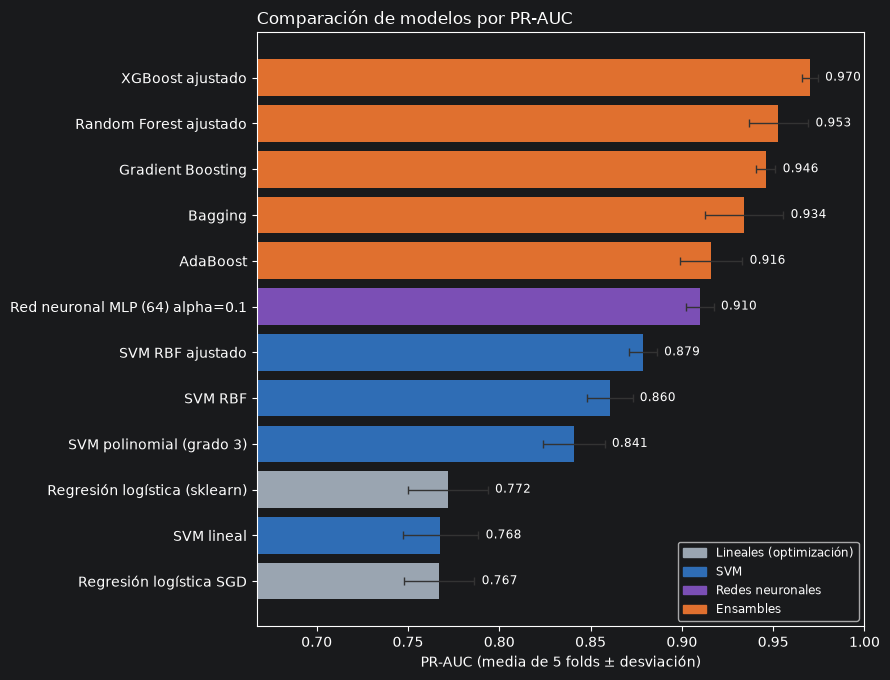

In [126]:
fig = plots.plot_model_comparison(all_summary, metric="PR-AUC")
viz.save_fig(fig, "10_model_comparison")

### Conclusiones: modelado

**Criterio de selección.** Los modelos se comparan por **PR-AUC** en validación cruzada (5 folds sobre el train), porque:
- Mide qué tan bien el modelo **ordena** a los clientes por riesgo, que es como el banco va a usarlo (priorizar a quién ofrecer beneficios), sin depender de un umbral.
- Es exigente con el desbalance: un modelo al azar obtiene **0,161** (la proporción de churn), mientras que en ROC-AUC obtendría 0,5. Con 84% de clientes que se quedan, la ROC-AUC es demasiado optimista: la regresión logística tiene ROC-AUC **0,935** pero PR-AUC **0,772**.
- Como criterios secundarios se usan la estabilidad entre folds (desviación), ROC-AUC, Recall y Precision con umbral 0,5, y el tiempo de entrenamiento.


**Modelo elegido: XGBoost ajustado** (`learning_rate` = 0,3, `max_depth` = 3, 300 árboles, `scale_pos_weight`):
- El mayor **PR-AUC (0,970)** y **ROC-AUC (0,993)** de todos los modelos.
- El mejor equilibrio con umbral 0,5: **Recall 0,924** y **Precision 0,897**.
- El más estable: desviación de PR-AUC de solo **0,004** entre folds.
- Entrena en fracciones de segundo, lo que facilita reentrenarlo periódicamente.
- Random Forest ajustado (**0,953**) queda como alternativa, por ser el segundo mejor y de una familia distinta (bagging).

## 5. Evaluación

### 5.1 Umbral de decisión
El modelo entrega una **probabilidad de churn** para cada cliente. Para decidir a quién marcar como "se va" hay que elegir un **umbral**: si la probabilidad es mayor o igual al umbral, el cliente se marca.
- **Umbral bajo:** se marcan más clientes, se detectan más churners (más **Recall**), pero también se marca a más clientes que no se iban a ir (menos **Precision**).
- **Umbral alto:** se marcan menos clientes y con más acierto, pero se escapan más churners.

In [128]:
best_model = models.xgboost_pipeline(y_train, **{k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()})

In [129]:
oof_proba = metrics.oof_probabilities(best_model, X_train, y_train)

In [130]:
oof_proba.describe().to_frame()

,prob_churn
count,"8,101.000"
mean,0.168
std,0.353
min,0.000
25%,0.000
50%,0.000
75%,0.014
max,1.000


In [131]:
thr_table = metrics.threshold_table(y_train, oof_proba)
f1_threshold, f1_row = metrics.best_f1_threshold(y_train, oof_proba)
display(thr_table)
print(f"Umbral que maximiza el F1: {f1_threshold:.2f}")
display(f1_row)

,Recall,Precision,F1,% clientes marcados,churners detectados,falsos positivos
umbral,,,,,,
0.050,0.981,0.737,0.842,21.392,1277,456
0.100,0.972,0.786,0.870,19.874,1266,344
0.150,0.966,0.813,0.883,19.109,1258,290
0.200,0.960,0.834,0.893,18.492,1250,248
0.250,0.957,0.849,0.900,18.109,1246,221
0.300,0.949,0.861,0.902,17.714,1235,200
0.350,0.942,0.871,0.906,17.381,1227,181
0.400,0.937,0.882,0.908,17.084,1220,164
0.450,0.929,0.891,0.910,16.763,1210,148


Umbral que maximiza el F1: 0.65


,Recall,Precision,F1,% clientes marcados,churners detectados,falsos positivos
umbral,,,,,,
0.650,0.902,0.924,0.913,15.689,1174,97


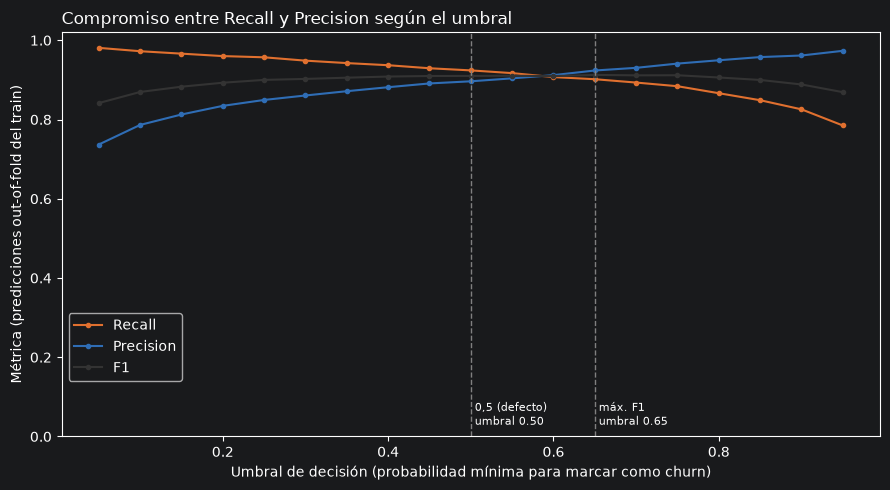

In [132]:
fig = plots.plot_threshold_curves(thr_table, marks={"0,5 (defecto)": 0.5, "máx. F1": f1_threshold})
viz.save_fig(fig, "11_threshold_curves")

- El compromiso es claro: al subir el umbral de **0,05** a **0,95** el Recall baja de **0,981** a **0,785** y la Precision sube de **0,737** a **0,973**.
- El **F1 es casi plano** entre umbrales de **0,30** y **0,75** (entre **0,902** y **0,913**). El modelo separa tan bien a las clases que el umbral exacto cambia poco el equilibrio general; lo que cambia es **cuántos churners se detectan frente a cuántos clientes se marcan por error**.
- Con el umbral por defecto (**0,50**) se detectan **1.203** de los 1.302 churners del train, con **139** falsos positivos. Con el umbral de máximo F1 (**0,65**) se detectan **1.174** con solo **97** falsos positivos.
- Como el F1 casi no distingue entre esos umbrales, la elección debe hacerse con **criterios de negocio**: cuánto cuesta ofrecer el beneficio a un cliente que no se iba a ir (falso positivo) frente a cuánto se pierde si se escapa un churner (falso negativo). Ese análisis se hace en la sección de impacto de negocio con **simulación Montecarlo**.

### 5.2 Evaluación final en el test

Se usa el umbral de referencia de la sección 5.1 (máximo F1 = 0,65).

In [133]:
final_model = best_model.fit(X_train, y_train)

In [134]:
test_proba = pd.Series(final_model.predict_proba(X_test)[:, 1], index=X_test.index, name="prob_churn")

In [135]:
test_metrics = metrics.evaluate_predictions(y_test, test_proba, threshold=f1_threshold)

In [136]:
metrics.compare_with_cv(test_metrics, y_train, oof_proba, threshold=f1_threshold)

,validación cruzada (umbral 0.65),test (umbral 0.65),diferencia
Recall,0.902,0.895,-0.006
Precision,0.924,0.939,0.015
F1,0.913,0.917,0.004
ROC-AUC,0.993,0.993,0.000
PR-AUC,0.970,0.968,-0.002
Accuracy balanceada,0.944,0.942,-0.002
Accuracy,0.972,0.974,0.002


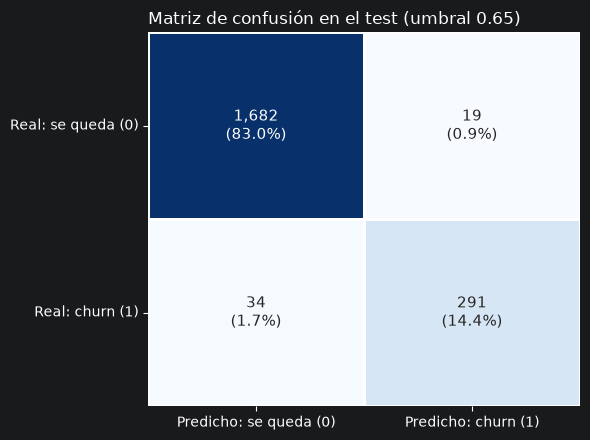

In [137]:
cm_table = metrics.confusion_table(y_test, test_proba, threshold=f1_threshold)
fig = plots.plot_confusion_matrix(cm_table, title=f"Matriz de confusión en el test (umbral {f1_threshold:.2f})")
viz.save_fig(fig, "12_confusion_matrix_test")

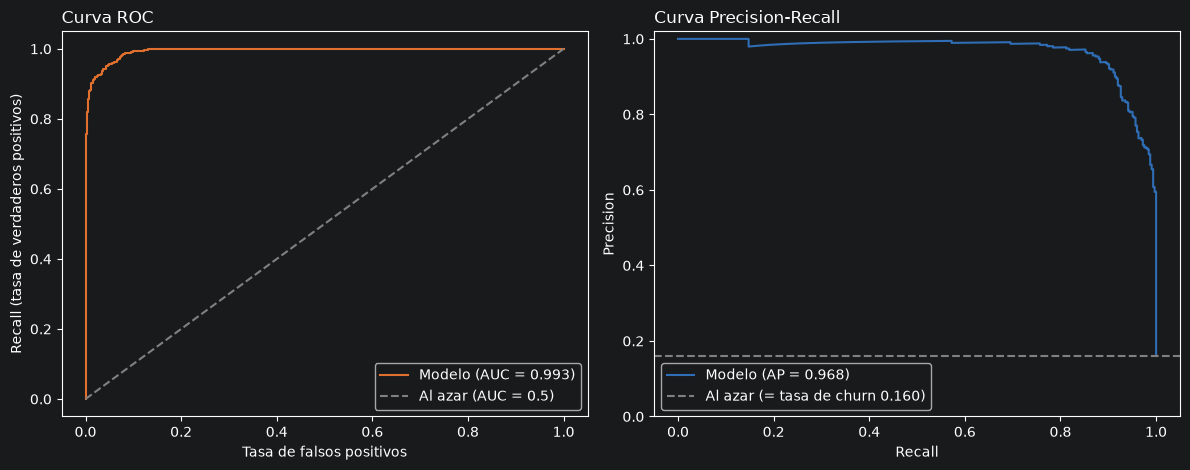

In [138]:
fig = plots.plot_roc_pr_curves(y_test, test_proba)
viz.save_fig(fig, "13_roc_pr_test")

In [139]:
test_deciles = metrics.decile_table(y_test, test_proba)
test_deciles

,clientes,prob. mínima,prob. media,churners,tasa de churn %,% clientes contactados (acum.),% churners capturados (acum.),lift
decil,,,,,,,,
1,203,0.992,0.999,201,99.015,10.020,61.846,6.172
2,203,0.080,0.599,111,54.680,20.039,96.000,3.409
3,202,0.004,0.023,13,6.436,30.010,100.000,0.401
4,203,0.001,0.002,0,0.000,40.030,100.000,0.000
5,202,0.000,0.000,0,0.000,50.000,100.000,0.000
6,203,0.000,0.000,0,0.000,60.020,100.000,0.000
7,203,0.000,0.000,0,0.000,70.039,100.000,0.000
8,202,0.000,0.000,0,0.000,80.010,100.000,0.000
9,203,0.000,0.000,0,0.000,90.030,100.000,0.000


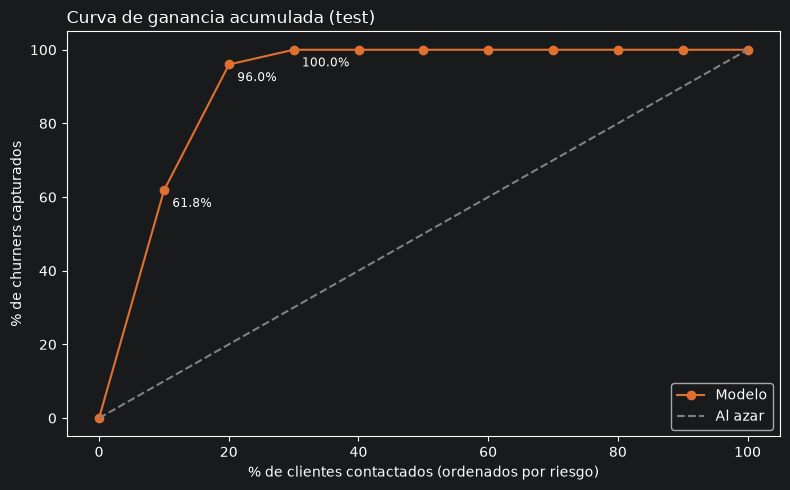

In [140]:
fig = plots.plot_gain_curve(test_deciles)
viz.save_fig(fig, "14_gain_curve_test")

- **El modelo generaliza:** las métricas en el test son prácticamente iguales a las de validación cruzada. No hay sobreajuste y el desempeño esperado con clientes nuevos es confiable.
- **Matriz de confusión** (umbral 0,65): de los **325** churners del test, el modelo detecta **291** (Recall **0,895**) y se le escapan **34**. Solo marca por error a **19** de los 1.701 clientes que se quedan. De cada 100 clientes que marca, unos 94 se van de verdad (Precision **0,939**).
- **Priorización (deciles):** el modelo concentra casi todo el riesgo al inicio de la lista:
  - El **10%** de clientes con mayor probabilidad (203 clientes) contiene **201 churners**: tasa de churn de **99,015%** y **lift de 6,172** (6 veces más churn que elegir al azar). Solo con ese grupo se captura el **61,8%** de todos los churners (curva de ganancia).
  - Contactando al **20%** de mayor riesgo se captura el **96,0%** de los churners, y con el **30%** el **100%**.
  - Del decil 4 en adelante no hay ningún churner.
- **Lectura de negocio:** el banco **no necesita ofrecer beneficios a toda su base**. Con una campaña dirigida al 20% de clientes de mayor riesgo alcanzaría a casi todos los que se van a ir.